In [23]:
import re
import warnings

from imblearn.over_sampling import SMOTENC
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split,
)
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

warnings.filterwarnings("ignore")

In [ ]:
from bank_churn_predictions.config import PROCESSED_DATA_DIR
from bank_churn_predictions.dataset import load_stage1_data

In [2]:
df = load_stage1_data()

2026-10-09 17:35:44.345 | INFO     | bank_churn_predictions.dataset:load_stage1_data:16 - Loading stage 1 dataset from D:\Ravindu\Programming\My Roadmap\Phase 1\bank_churn_predictions\data\interim\stage_1_preprocessing.csv
2026-10-09 17:35:44.404 | INFO     | bank_churn_predictions.dataset:load_stage1_data:20 - Loaded 10000 rows and 11 columns


### Encoding Categorical Variables

In [26]:
df.Gender = df["Gender"].map(lambda x: 1 if x == "Male" else 0)
df = pd.concat([df, pd.get_dummies(df.Geography, drop_first=True)], axis=1)
df.drop("Geography", inplace=True, axis=1)

In [27]:
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Germany,Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,False,True


### Feature Engineering

In [28]:
balance_counts = pd.DataFrame((df["Balance"] == 0).astype(int).value_counts()).reset_index()
balance_counts["Balance"] = [
    "Number of People with a Balance of 0",
    "Number of People who don't have a Balance of 0 ",
]
balance_counts

,Balance,count
0,Number of People with a Balance of 0,6383
1,Number of People who don't have a Balance of 0,3617


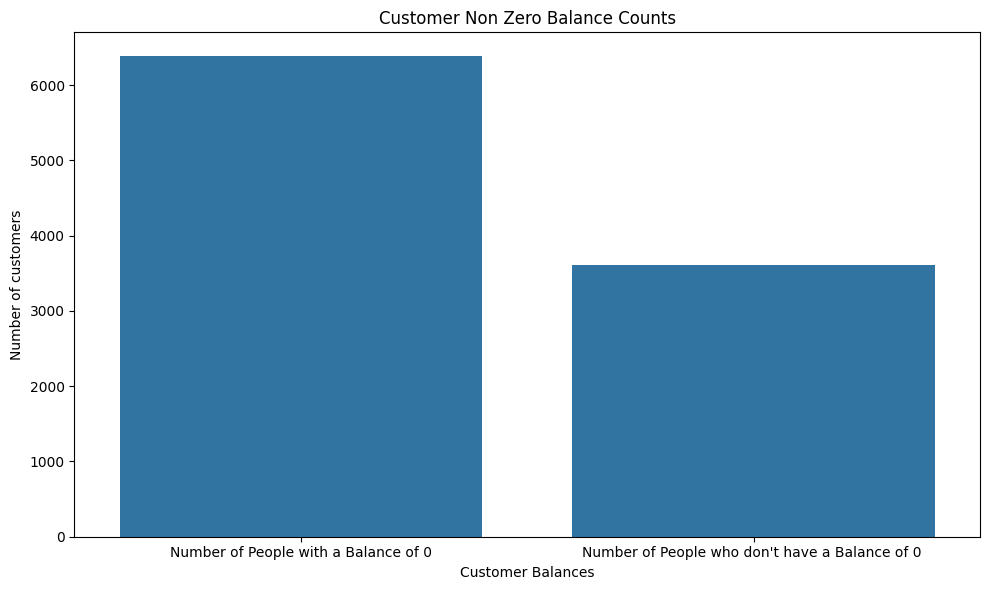

In [29]:
plt.figure(figsize=(10, 6))
sns.barplot(data=balance_counts, x="Balance", y="count")

plt.title("Customer Non Zero Balance Counts")
plt.xlabel("Customer Balances")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

<p>The boxplot indicated that the values in the balance column is mostly comprised of 0s, more than any other value, clearly indicated by the value counts here. This is a highly significant finding, and the prevalnce of this value for this feature justifies the creation of a seperate column to indicate whether the customer has or does not have savings within the bank. This allows a distinction that might not have been picked up ahd the column just been treated as one singular set of continous values</p>

In [30]:
df["HasBalance"] = (df["Balance"] > 0).astype(int)

In [31]:
bins = np.linspace(df.Age.min(), df.Age.max(), 7)  # -1 to avoid NAs
labels = [x for x in range(1, 7)]
print(bins)
df["Age_Group"] = pd.cut(df.Age, bins=bins, labels=labels, include_lowest=True)
df.groupby(pd.cut(df.Age, bins=bins, labels=labels))["Exited"].mean().reset_index()

[18.         30.33333333 42.66666667 55.         67.33333333 79.66666667
 92.        ]


,Age,Exited
0,1,0.075026
1,2,0.133126
2,3,0.435053
3,4,0.445724
4,5,0.124294
5,6,0.066667


<p>This grouping highlights a clear non linearity in the dataset. Different age groups represent different levels of Churn, with middle aged customers between the ages of 40 and 60 being much likelier to churn compared to other age groups.Therefore, its worth splitting them into seperate categorical features</p>

<p>I have decided to use both age and age groups instead of simply dropping age as this allows for continous and categorical information that models can use, instead of relying simply on a continous variable</p>

In [32]:
df.groupby("IsActiveMember")["Exited"].count()

IsActiveMember
0    4849
1    5151
Name: Exited, dtype: int64

<p>Suprisingly, there was next to no direct relationship between being an active member and churn rate. However, it is still our belief that the active status of members does have an important relationship with Churn, even though it may not be directly obvious. Therefore, Iwill investigate features that may be directly tied to a members active status</p>

In [33]:
df.groupby(["IsActiveMember", "NumOfProducts"])["Exited"].mean()

IsActiveMember  NumOfProducts
0               1                0.366521
                2                0.098881
                3                0.882353
                4                1.000000
1               1                0.189231
                2                0.055601
                3                0.752212
                4                1.000000
Name: Exited, dtype: float64

In [34]:
df["Active_x_Balance"] = df["IsActiveMember"] * df["HasBalance"]

<p>These observations reveal something interesting. Even though being an active member by itself does not correlate to Churn, its noticeable that when its put together with variables such as balance, there is a significant difference in the mean Churn rates, warranting the creation of seperate features to represent this relationship</p>

Text(0.5, 1.0, 'Heatmap displaying correlation relationships between all variables')

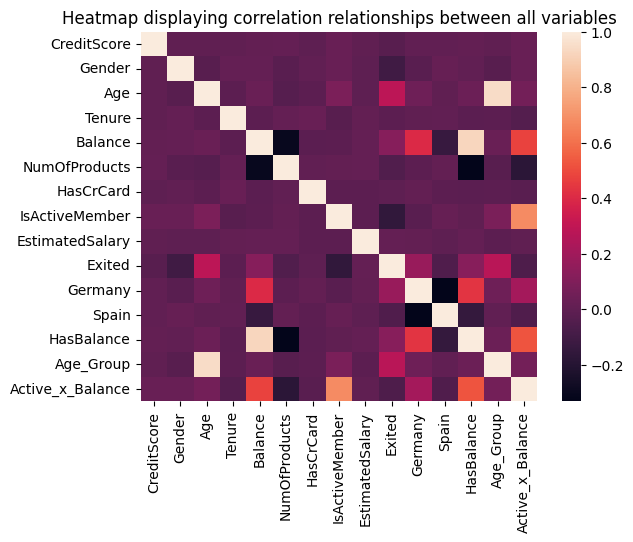

In [35]:
sns.heatmap(df.corr())
plt.title("Heatmap displaying correlation relationships between all variables")

### Scaling Discrete Numeric Variables

In [36]:
X = df.drop("Exited", axis=1)
y = df["Exited"]
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=49)

In [37]:
discrete_numeric = ["Tenure", "NumOfProducts", "Age_Group"]
cols_for_standard = ["CreditScore", "EstimatedSalary"]
cols_for_robust = ["Age", "Balance"]

numeric_pipeline = ColumnTransformer(
    transformers=[
        ("minmaxscaler", MinMaxScaler(), discrete_numeric),
        ("standardscaler", StandardScaler(), cols_for_standard),
        ("robustscaler", RobustScaler(), cols_for_robust),
    ],
    remainder="passthrough",
)

numeric_pipeline.fit(X_train)
transformed_feature_names = numeric_pipeline.get_feature_names_out()
print(transformed_feature_names)
for index, val in enumerate(transformed_feature_names):
    transformed_feature_names[index] = re.sub(r"^([a-z]*__)", "", transformed_feature_names[index])

X_train = pd.DataFrame(numeric_pipeline.transform(X_train), columns=transformed_feature_names)
X_test = pd.DataFrame(numeric_pipeline.transform(X_test), columns=transformed_feature_names)

['minmaxscaler__Tenure' 'minmaxscaler__NumOfProducts'
 'minmaxscaler__Age_Group' 'standardscaler__CreditScore'
 'standardscaler__EstimatedSalary' 'robustscaler__Age'
 'robustscaler__Balance' 'remainder__Gender' 'remainder__HasCrCard'
 'remainder__IsActiveMember' 'remainder__Germany' 'remainder__Spain'
 'remainder__HasBalance' 'remainder__Active_x_Balance']


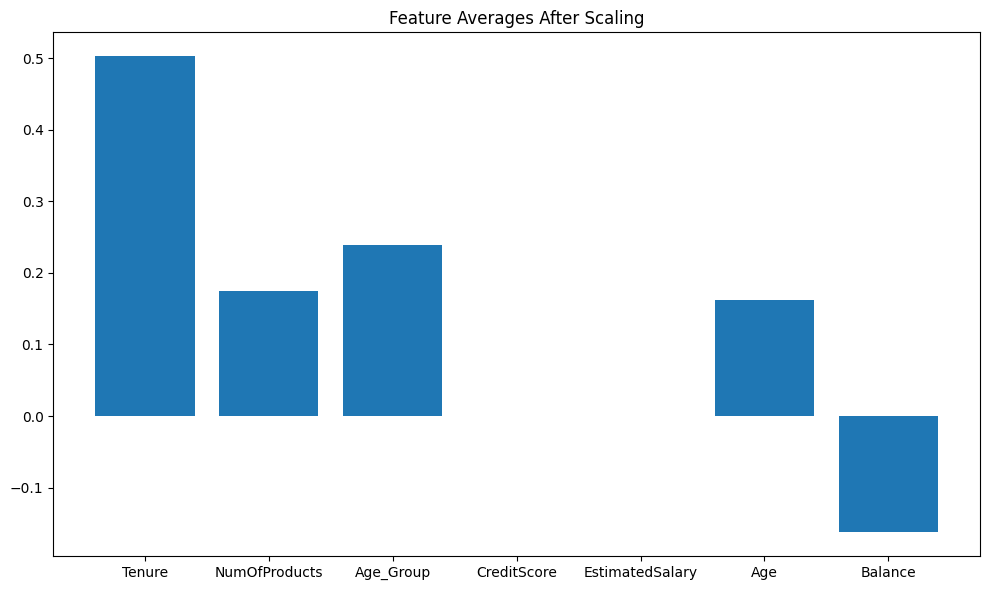

In [38]:
plt.figure(figsize=(10, 6))

all_cols_after_scaling = np.concatenate([discrete_numeric, cols_for_standard, cols_for_robust])
plt.bar(all_cols_after_scaling, X_train[all_cols_after_scaling].apply(lambda x: np.mean(x)))
plt.title("Feature Averages After Scaling")
plt.tight_layout()

<p>I think this covers all the immediately neessary forms of preprocessing. I might revisit this in the future but this is what ill currently go with. As you can see, the averages for each numeric feature is much more balanced now, allowing us to comfortably apply models that would otherwise be affected by different forms of scaling</p>
<p>Additionally, the heatmap does not reveal any significantly strongly correlated features with Exited, therefore I can conclude that there is no need for me to manually set feature importances for any models</p>

### Handling Class Imbalance

In [ ]:
cat_indices = [
    X_train.columns.get_loc(c)
    for c in [
        "HasBalance",
        "Age_Group",
        "Active_x_Balance",
        "Germany",
        "Spain",
        "Gender",
        "HasCrCard",
        "IsActiveMember",
    ]
]

smotenc = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_sm, y_train_sm = smotenc.fit_resample(X_train, y_train)
pd.concat([X_train_sm.reset_index(drop=True), y_train_sm.reset_index(drop=True)], axis=1).to_csv(
    PROCESSED_DATA_DIR / "SMOTE.csv", index=False
)

In [40]:
pd.concat([X_train.reset_index(drop=True), y_train.reset_index(drop=True)], axis=1).to_csv(
    PROCESSED_DATA_DIR / "train_data.csv", index=False
)
pd.concat([X_test.reset_index(drop=True), y_test.reset_index(drop=True)], axis=1).to_csv(
    PROCESSED_DATA_DIR / "test_data.csv", index=False
)

In [41]:
X_train_sm

,Tenure,NumOfProducts,Age_Group,CreditScore,EstimatedSalary,Age,Balance,Gender,HasCrCard,IsActiveMember,Germany,Spain,HasBalance,Active_x_Balance
0,0.2,0.333333,0.8,0.187926,-0.507845,2.916667,-0.763751,1,1,1,False,False,0,0
1,0.4,0.333333,0.4,1.277897,0.511638,1.083333,-0.763751,0,1,0,False,False,0,0
2,0.6,0.333333,0.0,-1.836305,-0.925895,-1.0,0.105123,0,0,0,False,False,1,0
3,0.4,0.0,0.8,0.177545,-0.096332,2.833333,0.313923,1,0,1,False,True,1,1
4,0.6,0.333333,0.6,0.499346,-0.477122,1.666667,0.30658,1,1,1,False,False,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11939,0.042149,0.093665,0.4,-0.979427,0.686516,1.535124,0.088389,0,0,1,True,False,1,1
11940,0.8,0.096738,0.2,0.924954,1.595374,0.236595,-0.763751,0,1,0,False,False,0,0
11941,0.755332,0.160742,0.2,-2.121749,0.022205,0.336296,0.309079,0,1,0,False,False,1,0
11942,0.247968,0.319784,0.6,-0.275745,-1.388064,1.366532,0.102604,0,1,0,True,False,1,0
